In [1]:
# Cell 1: Install Extra Dependencies, Mount Drive & Import Libraries
!pip -q install catboost

from google.colab import drive
import json
import os
import re
import joblib
import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/Airbnb Price Recommendor"
ARTIFACT_DIR = f"{DATA_DIR}/artifacts_ml"

Mounted at /content/drive


In [2]:
listings_raw = pd.read_csv(f"{DATA_DIR}/listings.csv.gz", low_memory=False)
print("Raw listings shape:", listings_raw.shape)

# Filter to listings with valid positive nightly prices (21,515 in NYC)
price_num = pd.to_numeric(
    listings_raw["price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce",
)
df = listings_raw[price_num.notna() & (price_num > 0)].copy()
df["price_num"] = price_num[price_num.notna() & (price_num > 0)]
df["log_price"] = np.log1p(df["price_num"])
print("Priced listings count:", len(df))

# Chunked calendar availability rate (avoids loading >11M rows all at once)
avail_true, avail_total = {}, {}
for ch in pd.read_csv(
    f"{DATA_DIR}/calendar.csv.gz",
    usecols=["listing_id", "available"],
    chunksize=500_000,
    low_memory=False,
):
  t_cnt = (ch["available"] == "t").groupby(ch["listing_id"]).sum()
  tot_cnt = ch.groupby("listing_id")["available"].count()
  for k, v in t_cnt.items():
    avail_true[k] = avail_true.get(k, 0) + int(v)
  for k, v in tot_cnt.items():
    avail_total[k] = avail_total.get(k, 0) + int(v)

cal_avail_series = pd.Series(
    {k: avail_true.get(k, 0) / v for k, v in avail_total.items() if v > 0},
    name="cal_avail_rate",
)
df = df.merge(cal_avail_series, left_on="id", right_index=True, how="left")

# Reviews count + interaction sparsity check
reviews_slim = pd.read_csv(
    f"{DATA_DIR}/reviews.csv.gz",
    usecols=["listing_id", "id", "reviewer_id"],
    low_memory=False,
)
rev_counts = reviews_slim.groupby("listing_id")["id"].count().rename("review_count")
df = df.merge(rev_counts, left_on="id", right_index=True, how="left")
df["review_count"] = df["review_count"].fillna(0)
df["review_log_count"] = np.log1p(df["review_count"])

n_rev = len(reviews_slim)
n_users = reviews_slim["reviewer_id"].nunique()
n_items = reviews_slim["listing_id"].nunique()
n_pairs = len(reviews_slim[["reviewer_id", "listing_id"]].drop_duplicates())
print(
    f"Reviews: {n_rev:,} | Reviewers: {n_users:,} | Reviewed listings:"
    f" {n_items:,} | Unique pairs: {n_pairs:,}"
)

Raw listings shape: (30259, 90)
Priced listings count: 21515
Reviews: 990,170 | Reviewers: 870,793 | Reviewed listings: 21,939 | Unique pairs: 969,131


In [3]:
# Cell 2B: Exploratory Collaborative Filtering Sparsity & SVD Diagnostic
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD

# Deduplicate reviewer-listing pairs to build binary implicit interaction matrix
pairs = reviews_slim[["reviewer_id", "listing_id"]].drop_duplicates()
user_codes, unique_users = pd.factorize(pairs["reviewer_id"])
item_codes, unique_items = pd.factorize(pairs["listing_id"])

R = csr_matrix(
    (np.ones(len(pairs), dtype=np.float32), (user_codes, item_codes)),
    shape=(len(unique_users), len(unique_items)),
)

sparsity_pct = 100.0 * (1.0 - R.nnz / (R.shape[0] * R.shape[1]))

# Item-item co-review overlap on active listings (restrict to items with >=5 reviews for fast exact check)
item_deg = np.asarray(R.sum(axis=0)).ravel()
active_mask = item_deg >= 5
R_act = R[:, active_mask]
co_matrix = (R_act.T @ R_act).tocoo()
off_diag = co_matrix.data[co_matrix.row < co_matrix.col]
pct_single_overlap = (
    100.0 * np.mean(off_diag == 1) if len(off_diag) > 0 else 0.0
)

# Exploratory TruncatedSVD variance explained
svd = TruncatedSVD(n_components=30, random_state=42)
svd.fit(R)
exp_var_30 = 100.0 * float(svd.explained_variance_ratio_.sum())

print(f"Interaction Matrix Shape: {R.shape[0]:,} reviewers x {R.shape[1]:,} listings")
print(f"Matrix Sparsity: {sparsity_pct:.6f}%")
print(f"Non-zero active listing pairs sharing only 1 reviewer: {pct_single_overlap:.2f}% (mean={off_diag.mean():.3f})")
print(f"TruncatedSVD (k=30) cumulative explained variance: {exp_var_30:.2f}%")
print("Scope Decision Confirmed: Sparsity too high for primary CF; using content-based retrieval as primary recommender.")

Interaction Matrix Shape: 870,793 reviewers x 21,939 listings
Matrix Sparsity: 99.994927%
Non-zero active listing pairs sharing only 1 reviewer: 95.52% (mean=1.068)
TruncatedSVD (k=30) cumulative explained variance: 3.68%
Scope Decision Confirmed: Sparsity too high for primary CF; using content-based retrieval as primary recommender.


In [4]:
# Cell 3: Full PRD Feature Engineering
def extract_bathrooms(text):
    if pd.isna(text):
        return np.nan
    t = str(text).lower().strip()
    if "half-bath" in t:
        return 0.5
    m = re.search(r"\d+(?:\.\d+)?", t)
    return float(m.group()) if m else np.nan

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp = np.radians(lat2 - lat1)
    dl = np.radians(lon2 - lon1)
    a = np.sin(dp / 2.0) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2.0) ** 2
    return 2.0 * r * np.arcsin(np.sqrt(a))

df["bathrooms_clean"] = pd.to_numeric(df["bathrooms"], errors="coerce").fillna(
    df["bathrooms_text"].apply(extract_bathrooms)
)
df["max_nights_clean"] = df["maximum_nights"].replace(2147483647, np.nan)
df["bedrooms_missing"] = df["bedrooms"].isna().astype(int)
df["host_is_superhost_bin"] = (df["host_is_superhost"] == "t").astype(int)
df["dist_midtown_km"] = haversine_km(df["latitude"], df["longitude"], 40.7580, -73.9855)

# Amenity count + 10 binary amenity indicators
df["amenity_count"] = df["amenities"].fillna("").apply(
    lambda s: len([x for x in s.split(",") if x.strip()]) if s.strip() not in ["", "[]"] else 0
)
amenity_keywords = {
    "amen_wifi": r"\bwifi\b",
    "amen_kitchen": r"\bkitchen\b",
    "amen_ac": r"air conditioning",
    "amen_heating": r"\bheating\b",
    "amen_washer": r"\bwasher\b",
    "amen_dryer": r"\bdryer\b",
    "amen_tv": r"\btv\b",
    "amen_self_checkin": r"self check-in",
    "amen_workspace": r"dedicated workspace",
    "amen_parking": r"free parking",
}
amen_lower = df["amenities"].fillna("").str.lower()
for col_name, pat in amenity_keywords.items():
    df[col_name] = amen_lower.str.contains(pat, regex=True).astype(int)

# Group rare property types cleanly
top_props = df["property_type"].value_counts().head(12).index
df["property_type_clean"] = df["property_type"].where(df["property_type"].isin(top_props), "Other")

num_cols = [
    "accommodates", "bedrooms", "bedrooms_missing", "beds", "bathrooms_clean",
    "minimum_nights", "max_nights_clean", "amenity_count",
    "cal_avail_rate", "review_log_count", "review_scores_rating",
    "host_is_superhost_bin", "calculated_host_listings_count",
    "latitude", "longitude", "dist_midtown_km",
] + list(amenity_keywords.keys())

cat_cols = ["room_type", "neighbourhood_group_cleansed", "property_type_clean"]

X = df[num_cols + cat_cols].copy()
y_raw = df["price_num"].copy()
y_log = df["log_price"].copy()
groups = df["host_id"]

print(f"Engineered features ready: {len(num_cols)} numerical + {len(cat_cols)} categorical columns")

Engineered features ready: 26 numerical + 3 categorical columns


In [5]:
# Cell 4: Host-Grouped Holdout Split & Preprocessing Pipeline
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(X, y_raw, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train_raw, y_test_raw = y_raw.iloc[train_idx], y_raw.iloc[test_idx]
y_train_log, y_test_log = y_log.iloc[train_idx], y_log.iloc[test_idx]
groups_train = groups.iloc[train_idx]

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cat_cols),
])

overlap_hosts = len(set(df.iloc[train_idx]["host_id"]) & set(df.iloc[test_idx]["host_id"]))
print(f"Train: {len(X_train):,} | Untouched Holdout Test: {len(X_test):,} | Host overlap: {overlap_hosts}")

Train: 16,874 | Untouched Holdout Test: 4,641 | Host overlap: 0


In [6]:
# Cell 5: 5-Fold GroupKFold CV — Training-Median Baseline + 8 Candidate Models (Log Target)
from sklearn.model_selection import GroupKFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor
!pip -q install catboost
from catboost import CatBoostRegressor

models_8 = {
    "Median Baseline": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10.0),
    "Elastic Net": ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=3000, random_state=42),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=15, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=150, max_depth=16, n_jobs=-1, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(
        n_estimators=250, learning_rate=0.06, max_depth=7,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1, verbosity=0
    ),
    "CatBoost": CatBoostRegressor(
        iterations=350, learning_rate=0.07, depth=7, verbose=0, random_seed=42
    ),
}

gkf = GroupKFold(n_splits=5)
cv_results = []

for name, estimator in models_8.items():
    fold_mae, fold_rmse, fold_r2 = [], [], []
    for tr_f, va_f in gkf.split(X_train, y_train_log, groups=groups_train):
        pipe = Pipeline([("prep", preprocessor), ("model", estimator)])
        pipe.fit(X_train.iloc[tr_f], y_train_log.iloc[tr_f])
        pred_log = pipe.predict(X_train.iloc[va_f])
        pred_dollar = np.clip(np.expm1(pred_log), 0.0, 50000.0)
        true_dollar = y_train_raw.iloc[va_f]

        fold_mae.append(mean_absolute_error(true_dollar, pred_dollar))
        fold_rmse.append(root_mean_squared_error(true_dollar, pred_dollar))
        fold_r2.append(r2_score(true_dollar, pred_dollar))

    cv_results.append({
        "Model": name,
        "CV MAE Mean ($)": round(float(np.mean(fold_mae)), 2),
        "CV MAE Std ($)": round(float(np.std(fold_mae)), 2),
        "CV RMSE Mean ($)": round(float(np.mean(fold_rmse)), 2),
        "CV RMSE Std ($)": round(float(np.std(fold_rmse)), 2),
        "CV R2 Mean": round(float(np.mean(fold_r2)), 4),
    })

cv_df = pd.DataFrame(cv_results).sort_values("CV MAE Mean ($)")
print("=== 5-FOLD GROUPKFOLD CV LEADERBOARD (ORIGINAL DOLLAR SCALE) ===")
print(cv_df.to_string(index=False))

# Select best non-baseline model based on 5-fold CV MAE
best_model_name = cv_df[cv_df["Model"] != "Median Baseline"].iloc[0]["Model"]
print("\nSelected Winning Model via 5-Fold CV:", best_model_name)

=== 5-FOLD GROUPKFOLD CV LEADERBOARD (ORIGINAL DOLLAR SCALE) ===
            Model  CV MAE Mean ($)  CV MAE Std ($)  CV RMSE Mean ($)  CV RMSE Std ($)  CV R2 Mean
         CatBoost           101.49           20.94            383.26           143.78      0.3452
          XGBoost           101.82           19.43            385.28           139.49      0.3352
Gradient Boosting           107.04           21.40            394.24           142.43      0.3038
    Random Forest           107.76           19.91            396.41           141.73      0.2949
            Ridge           121.99           21.17            408.37           138.05      0.2461
Linear Regression           121.99           21.26            408.31           138.10      0.2463
    Decision Tree           122.26           18.90            412.98           136.96      0.2262
      Elastic Net           125.13           20.80            414.30           136.25      0.2214
  Median Baseline           177.31           22.46   

In [7]:
# Cell 6: Untouched Holdout Evaluation, Segment Diagnostics & Feature Importance
from sklearn.inspection import permutation_importance

best_pipeline = Pipeline(
    [("prep", preprocessor), ("model", models_8[best_model_name])]
)
best_pipeline.fit(X_train, y_train_log)

holdout_preds = np.clip(np.expm1(best_pipeline.predict(X_test)), 0.0, 50000.0)

holdout_metrics = {
    "model": best_model_name,
    "holdout_mae": round(
        float(mean_absolute_error(y_test_raw, holdout_preds)), 2
    ),
    "holdout_rmse": round(
        float(root_mean_squared_error(y_test_raw, holdout_preds)), 2
    ),
    "holdout_r2": round(float(r2_score(y_test_raw, holdout_preds)), 4),
    "holdout_median_ae": round(
        float(np.median(np.abs(y_test_raw - holdout_preds))), 2
    ),
}
print("=== UNTOUCHED HOLDOUT TEST METRICS ===")
print(holdout_metrics)

# Error breakdown by price tier
std_mask = y_test_raw <= 750
lux_mask = y_test_raw > 750
print(
    f"\nStandard (<= $750, n={std_mask.sum():,}): "
    f"MAE=${mean_absolute_error(y_test_raw[std_mask], holdout_preds[std_mask]):.2f}, "
    f"RMSE=${root_mean_squared_error(y_test_raw[std_mask], holdout_preds[std_mask]):.2f}"
)
print(
    f"Luxury   (> $750,  n={lux_mask.sum():,}): "
    f"MAE=${mean_absolute_error(y_test_raw[lux_mask], holdout_preds[lux_mask]):.2f}, "
    f"RMSE=${root_mean_squared_error(y_test_raw[lux_mask], holdout_preds[lux_mask]):.2f}"
)

# Error breakdown by room_type
print("\n=== HOLDOUT ERROR BY ROOM TYPE ===")
for rt, grp in X_test.groupby("room_type"):
  idx_rt = grp.index
  pos_rt = X_test.index.get_indexer(idx_rt)
  print(
      f"  {rt:<18} (n={len(idx_rt):,}):"
      f" MAE=${mean_absolute_error(y_test_raw.loc[idx_rt], holdout_preds[pos_rt]):.2f}"
  )

# Top 10 feature drivers via permutation importance on holdout
perm = permutation_importance(
    best_pipeline, X_test, y_test_log, n_repeats=5, random_state=42, n_jobs=-1
)
fi_df = (
    pd.DataFrame(
        {"Feature": X_test.columns, "Importance_Mean": perm.importances_mean}
    )
    .sort_values("Importance_Mean", ascending=False)
    .head(10)
)
print("\n=== TOP 10 PRICE DRIVERS (PERMUTATION IMPORTANCE) ===")
print(fi_df.to_string(index=False))

=== UNTOUCHED HOLDOUT TEST METRICS ===
{'model': 'CatBoost', 'holdout_mae': 100.6, 'holdout_rmse': 545.57, 'holdout_r2': 0.3568, 'holdout_median_ae': 31.34}

Standard (<= $750, n=4,410): MAE=$51.92, RMSE=$84.37
Luxury   (> $750,  n=231): MAE=$1029.90, RMSE=$2417.47

=== HOLDOUT ERROR BY ROOM TYPE ===
  Entire home/apt    (n=2,298): MAE=$96.42
  Hotel room         (n=184): MAE=$706.08
  Private room       (n=2,122): MAE=$53.10
  Shared room        (n=37): MAE=$73.79

=== TOP 10 PRICE DRIVERS (PERMUTATION IMPORTANCE) ===
             Feature  Importance_Mean
      minimum_nights         0.367965
     dist_midtown_km         0.122982
        accommodates         0.121811
      cal_avail_rate         0.048914
           longitude         0.048153
           room_type         0.029880
     bathrooms_clean         0.028337
            bedrooms         0.023570
review_scores_rating         0.014780
 property_type_clean         0.013643


In [8]:
# Cell 7: PRD Tiered, Weighted & Host-Diversified Comparable-Listing Recommender
def retrieve_prd_comparables(
    target_row, catalog, top_k=10, exclude_listing_id=None
):
  pool = catalog[catalog["room_type"] == target_row["room_type"]].copy()
  if exclude_listing_id is not None:
    pool = pool[pool["id"] != exclude_listing_id]
  if "host_id" in target_row and pd.notna(target_row["host_id"]):
    pool = pool[pool["host_id"] != target_row["host_id"]]

  pool["geo_km"] = haversine_km(
      float(target_row["latitude"]),
      float(target_row["longitude"]),
      pool["latitude"].values,
      pool["longitude"].values,
  )
  cap_diff = (pool["accommodates"] - float(target_row["accommodates"])).abs()

  # Nested PRD eligibility tiers
  t1 = pool[(pool["geo_km"] <= 2.0) & (cap_diff == 0)]
  t2 = pool[(pool["geo_km"] <= 5.0) & (cap_diff == 0)]
  t3 = pool[(pool["geo_km"] <= 5.0) & (cap_diff <= 1)]

  if len(t1) >= top_k:
    cand, tier_used = t1.copy(), "Tier 1 (<=2 km, exact capacity)"
  elif len(t2) >= top_k:
    cand, tier_used = t2.copy(), "Tier 2 (<=5 km, exact capacity)"
  elif len(t3) >= top_k:
    cand, tier_used = t3.copy(), "Tier 3 (<=5 km, capacity +/-1)"
  else:
    cand, tier_used = (
        pool.nsmallest(max(50, top_k * 5), "geo_km").copy(),
        "Fallback (nearest same room_type)",
    )

  # Weighted similarity: geography 0.30, accommodation 0.25, property type 0.15, amenities 0.20, neighbourhood 0.10
  sim_geo = np.exp(-cand["geo_km"] / 2.0)
  sim_cap = 1.0 / (
      1.0 + (cand["accommodates"] - float(target_row["accommodates"])).abs()
  )
  sim_prop = (
      cand["property_type_clean"] == target_row["property_type_clean"]
  ).astype(float)
  amen_diff = (cand["amenity_count"] - float(target_row["amenity_count"])).abs()
  sim_amen = 1.0 / (1.0 + amen_diff / 10.0)
  sim_hood = (
      cand["neighbourhood_cleansed"]
      == target_row.get("neighbourhood_cleansed", "")
  ).astype(float)

  cand["similarity_score"] = (
      0.30 * sim_geo
      + 0.25 * sim_cap
      + 0.15 * sim_prop
      + 0.20 * sim_amen
      + 0.10 * sim_hood
  )
  cand = cand.sort_values("similarity_score", ascending=False)

  # Host diversification: max 1 listing per host_id
  diversified = cand.drop_duplicates(subset=["host_id"], keep="first").head(
      top_k
  )

  prices = diversified["price_num"].values
  ref_stats = {
      "tier_used": tier_used,
      "candidate_pool_size": int(len(cand)),
      "comparable_median": (
          round(float(np.median(prices)), 2) if len(prices) else None
      ),
      "comparable_q25": (
          round(float(np.percentile(prices, 25)), 2) if len(prices) else None
      ),
      "comparable_q75": (
          round(float(np.percentile(prices, 75)), 2) if len(prices) else None
      ),
  }
  return diversified, ref_stats


sample_target = (
    df[df["id"] == 2539].iloc[0] if (df["id"] == 2539).any() else df.iloc[0]
)
comps_df, ref_info = retrieve_prd_comparables(
    sample_target, df, top_k=5, exclude_listing_id=int(sample_target["id"])
)
print("Sample PRD Comparable Reference:", ref_info)
print(
    comps_df[[
        "id",
        "name",
        "neighbourhood_cleansed",
        "room_type",
        "accommodates",
        "price_num",
        "geo_km",
        "similarity_score",
    ]].to_string(index=False)
)

Sample PRD Comparable Reference: {'tier_used': 'Tier 1 (<=2 km, exact capacity)', 'candidate_pool_size': 137, 'comparable_median': 217.5, 'comparable_q25': 170.07, 'comparable_q75': 249.5}
                 id                                              name neighbourhood_cleansed    room_type  accommodates  price_num   geo_km  similarity_score
 670433084394073293       Spacious, exposed brick room w/private bath             Kensington Private room             2     249.50 0.318132          0.730882
           52142843         Room in Condo in Ditmas Park-shared space               Flatbush Private room             2     170.07 1.478115          0.709936
            1251681                 Room in Brooklyn. Stay with Maggy             Kensington Private room             2     217.50 0.121762          0.684912
1621230344436794478 Brooklyn Charm By Prospect Park (3 Min To Subway)               Flatbush Private room             2     628.00 1.198454          0.670034
           28560765  

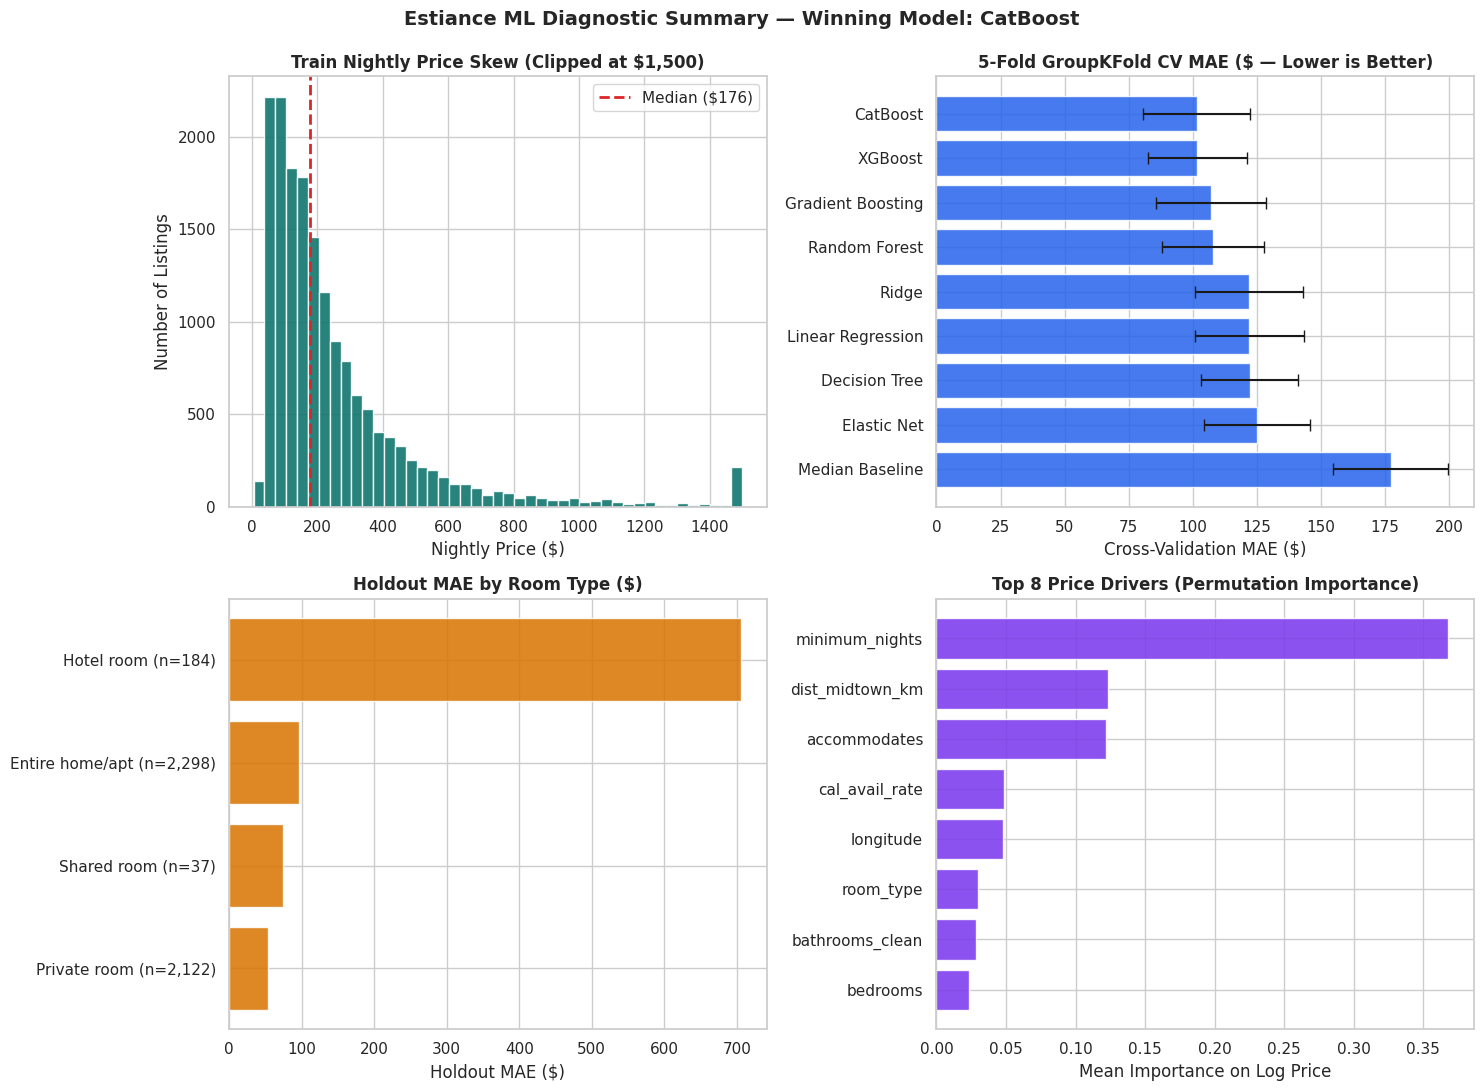

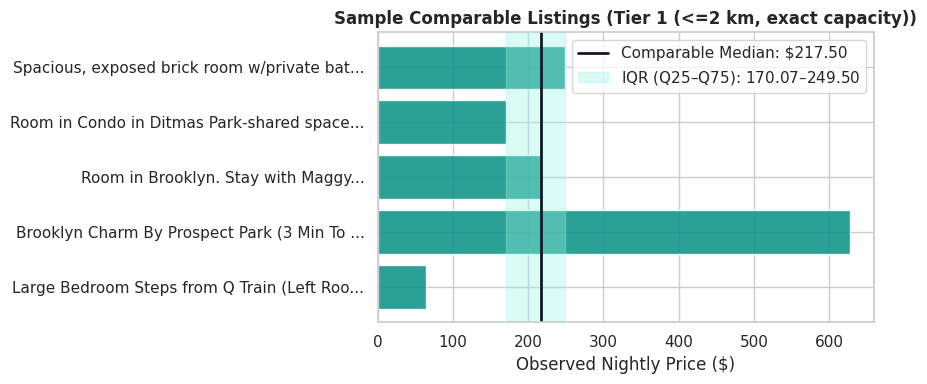

In [9]:
# Visualization Cell: EDA Price Skew, 5-Fold CV Leaderboard, Holdout Room-Type MAE & Feature Drivers
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Raw nightly price distribution (clipped at $1,500 to show skew clearly)
clipped_prices = np.clip(y_train_raw, 0, 1500)
axes[0, 0].hist(
    clipped_prices, bins=45, color="#0f766e", edgecolor="white", alpha=0.9
)
axes[0, 0].axvline(
    np.median(y_train_raw),
    color="#dc2626",
    linestyle="--",
    linewidth=2,
    label=f"Median (${np.median(y_train_raw):.0f})",
)
axes[0, 0].set_title(
    "Train Nightly Price Skew (Clipped at $1,500)",
    fontsize=12,
    fontweight="bold",
)
axes[0, 0].set_xlabel("Nightly Price ($)")
axes[0, 0].set_ylabel("Number of Listings")
axes[0, 0].legend()

# 2. 5-Fold GroupKFold CV MAE (Mean +/- Std) across baseline + 8 models
cv_plot = cv_df.iloc[::-1]
axes[0, 1].barh(
    cv_plot["Model"],
    cv_plot["CV MAE Mean ($)"],
    xerr=cv_plot["CV MAE Std ($)"],
    color="#2563eb",
    alpha=0.85,
    capsize=4,
)
axes[0, 1].set_title(
    "5-Fold GroupKFold CV MAE ($ — Lower is Better)",
    fontsize=12,
    fontweight="bold",
)
axes[0, 1].set_xlabel("Cross-Validation MAE ($)")

# 3. Untouched Holdout MAE by Room Type
rt_labels, rt_errors = [], []
for rt, grp in X_test.groupby("room_type"):
  pos_idx = X_test.index.get_indexer(grp.index)
  rt_labels.append(f"{rt} (n={len(grp):,})")
  rt_errors.append(
      mean_absolute_error(y_test_raw.loc[grp.index], holdout_preds[pos_idx])
  )

order_rt = np.argsort(rt_errors)
axes[1, 0].barh(
    [rt_labels[i] for i in order_rt],
    [rt_errors[i] for i in order_rt],
    color="#d97706",
    alpha=0.88,
)
axes[1, 0].set_title(
    "Holdout MAE by Room Type ($)", fontsize=12, fontweight="bold"
)
axes[1, 0].set_xlabel("Holdout MAE ($)")

# 4. Top 8 Feature Drivers by Permutation Importance
top_fi = fi_df.head(8).iloc[::-1]
axes[1, 1].barh(
    top_fi["Feature"], top_fi["Importance_Mean"], color="#7c3aed", alpha=0.88
)
axes[1, 1].set_title(
    "Top 8 Price Drivers (Permutation Importance)",
    fontsize=12,
    fontweight="bold",
)
axes[1, 1].set_xlabel("Mean Importance on Log Price")

plt.suptitle(
    f"Estiance ML Diagnostic Summary — Winning Model: {best_model_name}",
    fontsize=14,
    fontweight="bold",
    y=0.99,
)
plt.tight_layout()
plt.show()

# Bonus Chart: Comparable Listings Price Distribution vs Median & IQR for Sample Listing
if "comps_df" in globals() and len(comps_df) > 0:
  plt.figure(figsize=(9, 4))
  bars = plt.barh(
      comps_df["name"].astype(str).str.slice(0, 42) + "...",
      comps_df["price_num"],
      color="#0d9488",
      alpha=0.88,
  )
  if "ref_info" in globals() and ref_info.get("comparable_median") is not None:
    med_val = ref_info["comparable_median"]
    q25_val = ref_info.get("comparable_q25")
    q75_val = ref_info.get("comparable_q75")
    plt.axvline(
        med_val,
        color="#111827",
        linestyle="-",
        linewidth=2,
        label=f"Comparable Median: ${med_val:.2f}",
    )
    if q25_val is not None and q75_val is not None:
      plt.axvspan(
          q25_val,
          q75_val,
          color="#99f6e4",
          alpha=0.35,
          label=f"IQR (Q25–Q75): ${q25_val:.2f} – ${q75_val:.2f}",
      )
  plt.gca().invert_yaxis()
  plt.xlabel("Observed Nightly Price ($)")
  plt.title(
      f"Sample Comparable Listings ({ref_info.get('tier_used', 'PRD Tier')})",
      fontsize=12,
      fontweight="bold",
  )
  plt.legend()
  plt.tight_layout()
  plt.show()

In [10]:
# Cell 8: Export Versioned ML Artifacts & Reload Smoke Test
import os

os.makedirs(ARTIFACT_DIR, exist_ok=True)

joblib.dump(best_pipeline, f"{ARTIFACT_DIR}/best_price_model.joblib")

catalog_cols = [
    "id",
    "host_id",
    "name",
    "neighbourhood_group_cleansed",
    "neighbourhood_cleansed",
    "room_type",
    "property_type_clean",
    "accommodates",
    "bedrooms",
    "beds",
    "bathrooms_clean",
    "amenity_count",
    "latitude",
    "longitude",
    "price_num",
]
df[catalog_cols].to_parquet(
    f"{ARTIFACT_DIR}/listings_catalog.parquet", index=False
)

borough_to_hoods = (
    df.groupby("neighbourhood_group_cleansed")["neighbourhood_cleansed"]
    .unique()
    .apply(lambda arr: sorted([str(x) for x in arr if pd.notna(x)]))
    .to_dict()
)

ui_metadata = {
    "model_version": "estiance_v1_log_catboost",
    "best_model": best_model_name,
    "target_transform": "log1p",
    "cv_leaderboard": cv_df.to_dict(orient="records"),
    "holdout_metrics": holdout_metrics,
    "room_types": sorted(
        [str(x) for x in df["room_type"].dropna().unique()]
    ),
    "property_types": sorted(
        [str(x) for x in df["property_type_clean"].dropna().unique()]
    ),
    "boroughs": sorted(list(borough_to_hoods.keys())),
    "borough_to_neighbourhoods": borough_to_hoods,
    "defaults": {
        "accommodates": float(X_train["accommodates"].median()),
        "bedrooms": float(X_train["bedrooms"].median()),
        "beds": float(X_train["beds"].median()),
        "bathrooms_clean": float(X_train["bathrooms_clean"].median()),
        "minimum_nights": float(X_train["minimum_nights"].median()),
        "max_nights_clean": float(X_train["max_nights_clean"].median()),
        "amenity_count": float(X_train["amenity_count"].median()),
        "cal_avail_rate": float(X_train["cal_avail_rate"].median()),
        "review_log_count": float(X_train["review_log_count"].median()),
        "review_scores_rating": float(X_train["review_scores_rating"].median()),
        "host_is_superhost_bin": 0,
        "calculated_host_listings_count": 1.0,
        "latitude": float(X_train["latitude"].median()),
        "longitude": float(X_train["longitude"].median()),
    },
}

with open(f"{ARTIFACT_DIR}/ui_metadata.json", "w", encoding="utf-8") as f:
  json.dump(ui_metadata, f, indent=2)

# Reload verification
reloaded_model = joblib.load(f"{ARTIFACT_DIR}/best_price_model.joblib")
test_pred = float(np.expm1(reloaded_model.predict(X_test.iloc[[0]])[0]))
print(
    f"All PRD artifacts saved & verified in {ARTIFACT_DIR} | Sample reloaded"
    f" prediction: ${test_pred:.2f}"
)

All PRD artifacts saved & verified in /content/drive/MyDrive/Airbnb Price Recommendor/artifacts_ml | Sample reloaded prediction: $232.42
